<a href="https://colab.research.google.com/github/Riot808s/FUNDAI-Laboratories-Balona/blob/main/Lab7_Intro_to_ML_Balona.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 7: Supervised vs. Unsupervised Learning, Overfitting, and Cross-Validation

## Fundamentals of Artificial Intelligence

**Name:** Kylle Ian A. Balona

**Course:** BSCSAI

**Section:** 2A

**Date:** 10/20/2026

**Dataset Source (GitHub raw URL):**
https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv

**GitHub URL:** https://github.com/Riot808s/FUNDAI-Laboratories-Balona

## Description
This laboratory compares supervised and unsupervised learning, demonstrates overfitting and underfitting through a complexity sweep, and evaluates models using k-fold cross-validation.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
      accuracy_score,
      confusion_matrix,
      classification_report,
      adjusted_rand_score,
)

In [ ]:
GITHUB_RAW_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(GITHUB_RAW_URL)

print("Dataset shape:", df.shape)
print()
print(df.head())
print()
print("Class distribution:")
print(df["species"].value_counts())


Dataset shape: (150, 5)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:
feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

X = df[feature_columns].values
y = df["species"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.3,
    stratify = y,
    random_state = 42
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (105, 4)
Testing samples: (45, 4)


## Part A: Supervised Learning (Labels ARE Used)

The model learns a mapping from features to known labels. Scaling is placed INSIDE the pipeline so that each cross-validation fold computes scaling statistics from its training portion only. This prevents data leakage.

In [ ]:
supervised_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(max_depth = 3, random_state = 42))
])

supervised_pipeline.fit(X_train, y_train)

supervised_predictions = supervised_pipeline.predict(X_test)

print("SUPERVISED LEARNING RESULTS")
print("=" * 50)
print("Test accuracy:", accuracy_score(y_test, supervised_predictions))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, supervised_predictions))
print()
print(classification_report(y_test, supervised_predictions))

SUPERVISED LEARNING RESULTS
Test accuracy: 0.9777777777777777

Confusion Matrix:
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



## Part B: Unsupervised Learning (Labels ARE NOT Used)

the species column is completely ignored. K-Means must discover group structure on its own.
Afterwards, we compare the discovered clusters to the true labels only for evaluation purposes.

In [ ]:
# NOTE: y is NOT used anywhere in this part.
X_unlabeled = df[feature_columns].values

kmeans = KMeans(n_clusters = 3, n_init = 10, random_state = 42)
cluster_labels = kmeans.fit_predict(X_unlabeled)

comparison = pd.crosstab(
    pd.Series(cluster_labels, name = "Discovered Cluster"),
    pd.Series(y, name = "True Species")
)

print("UNSUPERVISED LEARNING RESULTS")
print("=" * 50)
print("Cluster vs. True Species crosstab:")
print(comparison)
print()
print("Adjusted Rand Index (cluster agreement with true labels):")
print(adjusted_rand_score(y, cluster_labels))

UNSUPERVISED LEARNING RESULTS
Cluster vs. True Species crosstab:
True Species        setosa  versicolor  virginica
Discovered Cluster                               
0                        0          48         14
1                       50           0          0
2                        0           2         36

Adjusted Rand Index (cluster agreement with true labels):
0.7302382722834697


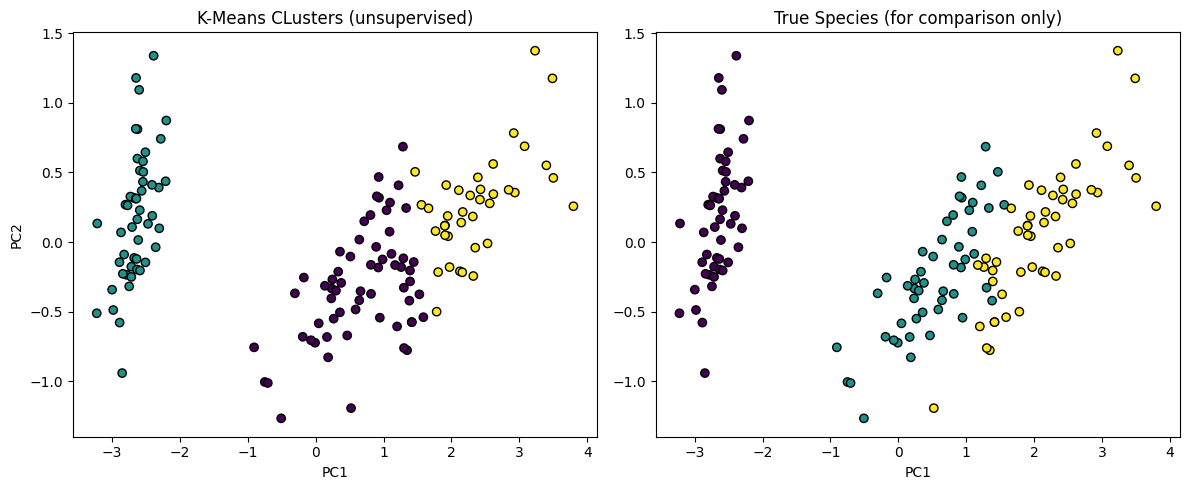

Explained variance ratio: [0.92461872 0.05306648]


In [ ]:
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_unlabeled)

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c = cluster_labels, cmap = "viridis", edgecolor = "k")
plt.title("K-Means CLusters (unsupervised)")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.subplot(1, 2, 2)
species_codes = pd.factorize(y)[0]
plt.scatter(X_pca[:, 0], X_pca[:, 1], c = species_codes, cmap = "viridis", edgecolor = "k")
plt.title("True Species (for comparison only)")
plt.xlabel("PC1")

plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)

## Part C: Complexity Sweep (Bias-Variance Demonstration)

We train decision trees with increasing max_depth.

- Very small depth -> high bias -> underfitiing
- Moderate depth   -> sweet spot -> good generalization
- Very Large depth -> high variance -> overfitting (train = 100%, gap widens)

In [ ]:
depth_values = list(range(1, 16))

train_scores = []
test_scores = []

for depth in depth_values:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth = depth, random_state = 42))
    ])

    pipe.fit(X_train, y_train)

    train_scores.append(accuracy_score(y_train, pipe.predict(X_train)))
    test_scores.append(accuracy_score(y_test, pipe.predict(X_test)))

sweep_table = pd.DataFrame({
    "max_depth": depth_values,
    "train_accuracy": train_scores,
    "test_accuracy": test_scores,
    "gap": np.array(train_scores) - np.array(test_scores)
})

print(sweep_table.to_string(index = False))

 max_depth  train_accuracy  test_accuracy      gap
         1        0.666667       0.666667 0.000000
         2        0.971429       0.888889 0.082540
         3        0.980952       0.977778 0.003175
         4        0.990476       0.888889 0.101587
         5        1.000000       0.911111 0.088889
         6        1.000000       0.911111 0.088889
         7        1.000000       0.911111 0.088889
         8        1.000000       0.911111 0.088889
         9        1.000000       0.911111 0.088889
        10        1.000000       0.911111 0.088889
        11        1.000000       0.911111 0.088889
        12        1.000000       0.911111 0.088889
        13        1.000000       0.911111 0.088889
        14        1.000000       0.911111 0.088889
        15        1.000000       0.911111 0.088889


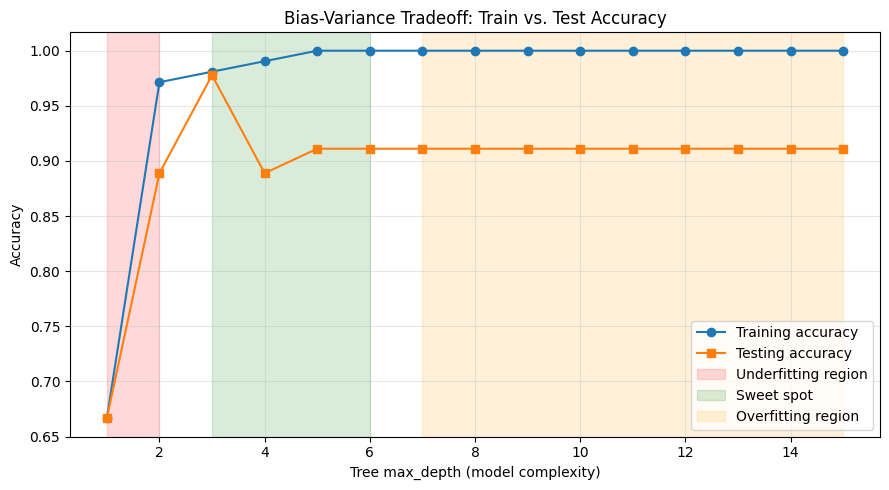

In [ ]:
plt.figure(figsize = (9, 5))

plt.plot(depth_values, train_scores, marker = "o", label = "Training accuracy")
plt.plot(depth_values, test_scores, marker = "s", label = "Testing accuracy")

plt.axvspan(1, 2, alpha = 0.15, color = "red", label = "Underfitting region")
plt.axvspan(3, 6, alpha = 0.15, color = "green", label = "Sweet spot")
plt.axvspan (7, 15, alpha = 0.15, color = "orange", label = "Overfitting region")

plt.xlabel("Tree max_depth (model complexity)")
plt.ylabel("Accuracy")
plt.title("Bias-Variance Tradeoff: Train vs. Test Accuracy")
plt.legend (loc = "lower right")
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

### Observed Regions (fill from your sweep table)

- Underfitting depth(s): [e.g., 1-2], because train and test accuracy are both low.
- Sweet-spot depth(s): [e.g., 3-6], because test accuracy is highest and the gap is small.
- Overfitting depth(s): [e.g., 8-15], because train accuracy reaches 1.0 while the train test gap widens.

## Part D: 5-Fold Stratified Cross-Validation
Cross-validation is run ONLY on the training set.
The held-out test set is never used for model selection.
Mean ± standard deviation shows both performance and stability.

In [ ]:
cv = StratifiedKFold (n_splits = 5, shuffle = True, random_state = 42)

models = {
    "Shallow tree (depth = 1, high bias)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=1, random_state=42))
    ]),
    "Moderate tree (depth = 4)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=4, random_state=42))
    ]),
    "Full tree (no depth limit, high variance)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=None, random_state=42))
    ]),
}

cv_results = []

for name, model in models.items():
    scores = cross_val_score (model, X_train, y_train, cv=cv, scoring="accuracy")

    cv_results.append({
        "Model": name,
        "CV mean": scores.mean(),
        "CV std": scores.std(),
        "Fold scores": np.round(scores, 3)
    })

    print(name)
    print("  Fold scores:", np.round(scores, 3))
    print(f"  Mean ± std {scores.mean():.3f} + {scores.std():.3f}")
    print("-" * 60)

cv_table = pd.DataFrame(cv_results)
print(cv_table.to_string(index = False))

Shallow tree (depth = 1, high bias)
  Fold scores: [0.667 0.667 0.667 0.667 0.667]
  Mean ± std 0.667 + 0.000
------------------------------------------------------------
Moderate tree (depth = 4)
  Fold scores: [0.905 0.952 0.905 0.952 0.952]
  Mean ± std 0.933 + 0.023
------------------------------------------------------------
Full tree (no depth limit, high variance)
  Fold scores: [0.905 0.952 0.905 0.952 0.952]
  Mean ± std 0.933 + 0.023
------------------------------------------------------------
                                    Model  CV mean   CV std                         Fold scores
      Shallow tree (depth = 1, high bias) 0.666667 0.000000 [0.667, 0.667, 0.667, 0.667, 0.667]
                Moderate tree (depth = 4) 0.933333 0.023328 [0.905, 0.952, 0.905, 0.952, 0.952]
Full tree (no depth limit, high variance) 0.933333 0.023328 [0.905, 0.952, 0.905, 0.952, 0.952]


### ⚠ Data Leakage Demonstration (DO NOT use in real projects)

Below, scaling is fitted on ALL data (including the test set) BEFORE cross-validation. This leaks test information into training and usually produces optimistically biased scores. Compare with the pipeline results above.


In [ ]:
leaky_scaler = StandardScaler().fit(X)          # WRONG: uses test data too
X_leaky = leaky_scaler.transform(X)

leaky_model = DecisionTreeClassifier(max_depth = 4, random_state = 42)

leaky_scores = cross_val_score(leaky_model, X_leaky, y, cv = cv, scoring = "accuracy")

print("Leaky CV mean:", leaky_scores.mean())
print("Difference vs. honest pipeline is usually small on this easy dataset,")
print("but on harder datasets leakage inflates scores dangerously.")

Leaky CV mean: 0.9533333333333335
Difference vs. honest pipeline is usually small on this easy dataset,
but on harder datasets leakage inflates scores dangerously.


## Guide Questions and Answers

### 1. Which part of this laboratory used supervised learning, and which used unsupervised learning?
**Answer:** Part A used supervised learning while Part B used unsupervised learning.

### 2. Did the K-Means clusters match the true species? Explain using the crosstab and Adjusted Rand Index.
**Answer:** The K-Means clusters mostly matched the true species. Setosa matched perfectly, but versicolor and virginica had a small overlap. With the Adjusted Rand Index being around 0.73, this shows good overall agreement with the true species.

### 3. Which max_depth value(s) showed underfitting? What evidence supports this?
**Answer:** A max_depth of 1 (and 2) showed underfitting. The evidence that supports this is that their train and test accuracies were both low.

### 4. Which max_depth value(s) showed overfitting? What evidence supports this?
**Answer:** The max_depth values from 7 to 15 showed overfitting. The evidence that supports this is that training accuracy reaches 100% while testing accuracy stays lower at 91.1% and it creates a large gap.

### 5. Why does training accuracy reach 100% at large depths?
**Answer:** At large depths, a decision tree can create many branches and learn very specific patterns in the training data, including noise and individual examples.

### 6. What do the CV mean and CV standard deviation tell you about a model?
**Answer:** The CV mean represents the model's average accuracy across the cross-validation folds, while the CV standard deviation indicates how much its accuracy varies between folds.

###7. Why must StandardScaler be placed inside the Pipeline?
**Answer:** StandardScaler must be inside the Pipeline to prevent data leakage. This ensures that the scaler is fitted only on each training fold and then applied to its corresponding validation fold, preventing information from the validation data from influencing preprocessing.

### 8. Connect your sweep curve to bias and variance.
**Answer:** At low max_depth values, the decision tree has high bias because it is too simple to capture the patterns in the data, leading to underfitting. As max_depth increases, the model becomes more complex and can learn the data better. However, at excessive depths, variance increases because the model becomes more sensitive to the training data, potentially causing overfitting. The goal is to find a depth that balances bias and variance and generalizes well to unseen data.

## Reflection

### Challenges Encountered
- Challenges encountered include accidentally inputting wrong values, getting the wrong results, and syntax errors.

### What I Learned
- I learned how supervised and unsupervised learning work and how they differ as well as understanding how machine-learning models work and how to evaluate their performance.